<a href="https://colab.research.google.com/github/techievansh/salon-causal-inference/blob/main/notebooks/Salon_Causal_Inference_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries
!pip install -q pandas numpy scipy statsmodels scikit-learn matplotlib seaborn openpyxl

In [2]:

# ============================================================
# SALON & SPA CAUSAL INFERENCE PROJECT
# FULL SYNTHETIC DATA GENERATOR
# ============================================================

import numpy as np
import pandas as pd
import zipfile
import os

np.random.seed(42)

OUTLETS = [f"OUT{i:02d}" for i in range(1, 23)]

# ------------------------------------------------------------
# DATASET 1: OPERATIONAL DATA - 300,000 RECORDS
# ------------------------------------------------------------

n = 300000

service_prices = {
    "Haircut": 500,
    "Hair Spa": 1500,
    "Facial": 1800,
    "Manicure": 700,
    "Pedicure": 800,
    "Massage": 2000
}

services = list(service_prices.keys())

service_aliases = {
    "Haircut": ["Haircut", "Hair Cut", "haircut"],
    "Hair Spa": ["Hair Spa", "Hair Treatment", "hair spa"],
    "Facial": ["Facial", "Skin Facial", "facial"],
    "Manicure": ["Manicure", "Mani Cure", "manicure"],
    "Pedicure": ["Pedicure", "Pedi Cure", "pedicure"],
    "Massage": ["Massage", "Body Massage", "massage"]
}

service = np.random.choice(services, n)
outlet_num = np.random.randint(1, 23, n)
outlet = np.array([f"OUT{i:02d}" for i in outlet_num])

walkin = np.random.binomial(1, 0.18, n)

customer_num = np.random.randint(1, 85001, n)
client_ids = np.array([f"C{i:06d}" for i in customer_num], dtype=object)
client_ids[walkin == 1] = None

# Actual status used internally by generator
actual_status = np.random.choice(
    ["Completed", "Cancelled", "No-show"],
    n,
    p=[0.78, 0.12, 0.10]
)

# Some no-shows incorrectly recorded as cancellations
recorded_status = actual_status.copy()
misclassified = (
    (actual_status == "No-show") &
    (np.random.random(n) < 0.75)
)
recorded_status[misclassified] = "Cancelled"

# Revenue
base_price = np.array([service_prices[x] for x in service])

service_revenue = np.where(
    actual_status == "Completed",
    base_price * np.random.uniform(0.85, 1.20, n),
    0
)

product_sales = np.where(
    actual_status == "Completed",
    np.random.choice(
        [0, 200, 400, 600, 1000],
        n,
        p=[0.45, 0.20, 0.18, 0.12, 0.05]
    ),
    0
)

service_raw = [
    np.random.choice(service_aliases[s]) for s in service
]

dates = pd.to_datetime(
    np.random.randint(
        pd.Timestamp("2025-01-01").value // 10**9,
        pd.Timestamp("2026-11-01").value // 10**9,
        n
    ),
    unit="s"
)

appointments = pd.DataFrame({
    "appointment_id": [f"APT{i:07d}" for i in range(n)],
    "client_id": client_ids,
    "outlet_id": outlet,
    "region": np.where(outlet_num <= 11, "Treatment", "Control"),
    "appointment_date": dates,
    "service_raw": service_raw,
    "stylist_id": [
        f"ST{i:03d}" for i in np.random.randint(1, 111, n)
    ],
    "walk_in": walkin,
    "appointment_status": recorded_status,
    "service_revenue": np.round(service_revenue, 2),
    "product_sales": product_sales,
    "total_revenue": np.round(service_revenue + product_sales, 2)
})

appointments.to_csv(
    "salon_appointments_synthetic_300k.csv", index=False
)

# ------------------------------------------------------------
# DATASET 2: RANDOMIZED A/B EXPERIMENT - 12,000 CUSTOMERS
# ------------------------------------------------------------

m = 12000

# Exactly 50% treatment and 50% control, randomized order
treatment = np.repeat([0, 1], m // 2)
np.random.shuffle(treatment)

baseline_revenue = np.random.normal(1100, 300, m).clip(100)
baseline_visits = np.random.poisson(3, m)
baseline_retention = np.random.binomial(1, 0.55, m)
baseline_no_show = np.random.binomial(1, 0.12, m)

# Treatment improves 90-day retention
retention_prob = np.clip(
    0.55 + 0.05 * treatment, 0, 1
)
retained = np.random.binomial(1, retention_prob)

# Treatment increases revenue per visit
revenue = np.random.normal(
    1200 + 25 * treatment
    + 0.35 * (baseline_revenue - 1100),
    350,
    m
).clip(100)

# Treatment reduces no-show probability
no_show_prob = 0.12 - 0.03 * treatment
no_show = np.random.binomial(1, no_show_prob)

experiment = pd.DataFrame({
    "customer_id": [f"EXP{i:06d}" for i in range(m)],
    "group": np.where(treatment == 1, "Treatment", "Control"),
    "treatment": treatment,
    "baseline_revenue": np.round(baseline_revenue, 2),
    "baseline_visits": baseline_visits,
    "baseline_retained": baseline_retention,
    "baseline_no_show": baseline_no_show,
    "retained_90d": retained,
    "revenue_per_visit": np.round(revenue, 2),
    "no_show": no_show,
    "outlet_id": np.random.choice(OUTLETS, m)
})

experiment.to_csv("ab_experiment_synthetic.csv", index=False)

# ------------------------------------------------------------
# DATASET 3: HISTORICAL DiD DATA - 22 OUTLETS x 40 WEEKS
# ------------------------------------------------------------

weeks = pd.date_range("2025-10-06", periods=40, freq="W-MON")
records = []

for i, outlet_id in enumerate(OUTLETS):

    treated = int(i < 11)
    outlet_effect = np.random.normal(0, 1.5)

    for t, week in enumerate(weeks):

        post = int(t >= 20)

        # Shared trend and seasonality
        trend = 0.25 * t
        seasonal = 5 * np.sin(2 * np.pi * t / 13)

        # Outcomes
        retention = (
            55 + outlet_effect + trend + seasonal
            + treated * post * 6
            + np.random.normal(0, 1.2)
        )

        revenue = (
            1100 + outlet_effect * 10 + 5 * t
            + 40 * seasonal
            + treated * post * 45
            + np.random.normal(0, 30)
        )

        no_show_rate = (
            12 - 0.04 * t + 0.15 * seasonal
            - treated * post * 2
            + np.random.normal(0, 0.5)
        )

        records.append({
            "outlet_id": outlet_id,
            "week": week,
            "region": "Treatment" if treated else "Control",
            "treatment": treated,
            "post": post,
            "retention_rate": np.clip(retention, 0, 100),
            "revenue_per_visit": max(0, revenue),
            "no_show_rate": np.clip(no_show_rate, 0, 100)
        })

historical = pd.DataFrame(records)

historical.to_csv("historical_did_synthetic.csv", index=False)

# ------------------------------------------------------------
# DATA DICTIONARY AND SYNTHETIC DATA DISCLOSURE
# ------------------------------------------------------------

documentation = """
PROJECT: Coimbatore Salon and Spa Causal Inference

IMPORTANT:
All three datasets are fully synthetic.
No real salon customer or business records were used.
The datasets are created for educational and methodological
demonstration only.

1. salon_appointments_synthetic_300k.csv
   300,000 appointment-level records across 22 outlets.
   Includes customer IDs, services, stylists, appointment
   status, service revenue and product sales.
   Deliberate issues: missing walk-in IDs, inconsistent
   service names and misclassified no-shows.

2. ab_experiment_synthetic.csv
   12,000 randomized customer-level experiment records.
   Treatment and control allocation is 50:50.
   Includes baseline variables and 90-day retention,
   revenue per visit and no-show outcomes.

3. historical_did_synthetic.csv
   880 outlet-week observations.
   Includes 11 treatment and 11 control outlets,
   20 pre-intervention and 20 post-intervention weeks.
   Includes seasonal variation and common trends.

Random seed: 42

Caution:
Results from synthetic data demonstrate analytical methods
and do not establish real-world business effectiveness.
"""

with open("DATA_DICTIONARY.txt", "w") as f:
    f.write(documentation)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("=" * 55)
print("DATA GENERATION SUCCESSFUL")
print("=" * 55)

print("\nOperational Dataset:", appointments.shape)
print("A/B Experiment Dataset:", experiment.shape)
print("Historical DiD Dataset:", historical.shape)

print("\nNumber of Outlets:", appointments.outlet_id.nunique())
print("\nA/B Group Distribution:")
print(experiment.group.value_counts())

print("\nHistorical Regions:")
print(historical.region.value_counts())

# ------------------------------------------------------------
# CREATE ZIP
# ------------------------------------------------------------

files_to_zip = [
    "salon_appointments_synthetic_300k.csv",
    "ab_experiment_synthetic.csv",
    "historical_did_synthetic.csv",
    "DATA_DICTIONARY.txt"
]

with zipfile.ZipFile("Salon_Causal_Inference_Datasets.zip", "w") as z:
    for file in files_to_zip:
        z.write(file)

print("\nZIP FILE CREATED SUCCESSFULLY!")
print("Salon_Causal_Inference_Datasets.zip")

from google.colab import files
files.download("Salon_Causal_Inference_Datasets.zip")


DATA GENERATION SUCCESSFUL

Operational Dataset: (300000, 12)
A/B Experiment Dataset: (12000, 11)
Historical DiD Dataset: (880, 8)

Number of Outlets: 22

A/B Group Distribution:
group
Control      6000
Treatment    6000
Name: count, dtype: int64

Historical Regions:
region
Treatment    440
Control      440
Name: count, dtype: int64

ZIP FILE CREATED SUCCESSFULLY!
Salon_Causal_Inference_Datasets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# =====================================================
# STEP 2: DATA CLEANING AND DATA QUALITY ANALYSIS
# =====================================================

import pandas as pd
import numpy as np

# Load generated dataset
df = appointments.copy()

print("Original Shape:", df.shape)

# 1. Check duplicates
duplicates = df.duplicated(subset=["appointment_id"]).sum()
df = df.drop_duplicates(subset=["appointment_id"])

# 2. Standardize service names
service_mapping = {
    "Haircut": "Haircut",
    "Hair Cut": "Haircut",
    "haircut": "Haircut",
    "Hair Spa": "Hair Spa",
    "Hair Treatment": "Hair Spa",
    "hair spa": "Hair Spa",
    "Facial": "Facial",
    "Skin Facial": "Facial",
    "facial": "Facial",
    "Manicure": "Manicure",
    "Mani Cure": "Manicure",
    "manicure": "Manicure",
    "Pedicure": "Pedicure",
    "Pedi Cure": "Pedicure",
    "pedicure": "Pedicure",
    "Massage": "Massage",
    "Body Massage": "Massage",
    "massage": "Massage"
}

df["service_name"] = df["service_raw"].map(service_mapping)

# 3. Convert dates
df["appointment_date"] = pd.to_datetime(
    df["appointment_date"], errors="coerce"
)

# 4. Check missing customer IDs
missing_customer_ids = df["client_id"].isna().sum()

# Preserve anonymous walk-ins.
df["customer_type"] = np.where(
    df["walk_in"] == 1,
    "Walk-in",
    "Registered"
)

# 5. Check status distribution
status_distribution = df["appointment_status"].value_counts()

# 6. Revenue validation
df["total_revenue"] = (
    df["service_revenue"] + df["product_sales"]
)

# 7. Check invalid values
invalid_revenue = (df["total_revenue"] < 0).sum()
missing_services = df["service_name"].isna().sum()
missing_dates = df["appointment_date"].isna().sum()

# 8. Create cleaning report
cleaning_report = pd.DataFrame({
    "Quality Check": [
        "Original Records",
        "Duplicate Appointment IDs",
        "Missing Customer IDs",
        "Missing Service Names",
        "Missing Appointment Dates",
        "Negative Revenue Records"
    ],
    "Count": [
        len(appointments),
        duplicates,
        missing_customer_ids,
        missing_services,
        missing_dates,
        invalid_revenue
    ]
})

print("\nCLEANING REPORT")
display(cleaning_report)

print("\nSTANDARDIZED SERVICES")
display(df["service_name"].value_counts())

print("\nRECORDED APPOINTMENT STATUS")
display(status_distribution)

# IMPORTANT:
# No-show records were deliberately misclassified as cancellations.
# The true status was not included in the saved operational CSV.
# Therefore, we cannot reliably reconstruct actual no-shows.
# We will disclose this limitation and treat recorded cancellations
# as a potentially contaminated category.

print("\nNo-show data limitation documented.")

# 9. Save cleaned dataset
df.to_csv("salon_appointments_cleaned.csv", index=False)

cleaning_report.to_csv(
    "data_cleaning_report.csv", index=False
)

print("\nCLEANED DATASET SAVED SUCCESSFULLY!")
print("Final Shape:", df.shape)

Original Shape: (300000, 12)

CLEANING REPORT


,Quality Check,Count
0,Original Records,300000
1,Duplicate Appointment IDs,0
2,Missing Customer IDs,53918
3,Missing Service Names,0
4,Missing Appointment Dates,0
5,Negative Revenue Records,0



STANDARDIZED SERVICES


,count
service_name,
Pedicure,50277
Hair Spa,50262
Manicure,50056
Massage,49868
Haircut,49859
Facial,49678



RECORDED APPOINTMENT STATUS


,count
appointment_status,
Completed,233909
Cancelled,58613
No-show,7478



No-show data limitation documented.

CLEANED DATASET SAVED SUCCESSFULLY!
Final Shape: (300000, 14)


A/B Dataset Shape: (12000, 11)
Historical Dataset Shape: (880, 8)

========== 1. RANDOMISATION BALANCE ==========


,Treatment_Mean,Control_Mean,P_Value
Variable,,,
baseline_revenue,1098.621868,1096.847278,0.742836
baseline_visits,3.001167,2.996500,0.881706
baseline_retained,0.540500,0.540000,0.956182
baseline_no_show,0.115667,0.124333,0.144104



========== 2. SAMPLE RATIO MISMATCH ==========


,Observed_Count
Group,
Control,6000
Treatment,6000


Chi-square: 0.0
SRM p-value: 1.0
SRM Status: PASS

========== 3. A/B TEST RESULTS ==========

90-Day Retention
Treatment Mean: 0.6057
Control Mean: 0.5452
Effect: 0.0605
95% CI: 0.0428 to 0.0782
Bootstrap CI: 0.0433 to 0.0777
P-value: 0.0

Revenue Per Visit
Treatment Mean: 1226.0147
Control Mean: 1194.1766
Effect: 31.8381
95% CI: 18.7509 to 44.9252
Bootstrap CI: 18.4417 to 44.9594
P-value: 2e-06

No-Show Rate
Treatment Mean: 0.0887
Control Mean: 0.1222
Effect: -0.0335
95% CI: -0.0445 to -0.0225
Bootstrap CI: -0.0445 to -0.0223
P-value: 0.0


,Treatment_Mean,Control_Mean,Effect,CI_Lower,CI_Upper,Bootstrap_Lower,Bootstrap_Upper,P_Value
Metric,,,,,,,,
90-Day Retention,0.605667,0.545167,0.060500,0.042844,0.078156,0.043333,0.077671,1.949812e-11
Revenue Per Visit,1226.014723,1194.176627,31.838097,18.750949,44.925244,18.441727,44.959373,1.880266e-06
No-Show Rate,0.088667,0.122167,-0.033500,-0.044474,-0.022526,-0.044500,-0.022333,2.248258e-09


... (9 outputs left out)

,Value
Measure,
Pre-Trend Effect,0.002117
CI Lower,-0.034984
CI Upper,0.039219
P-Value,0.910935


Assessment: No statistically significant differential pre-trend detected

========== 8. CUSTOMER SEGMENTATION ==========


Treatment_N  Control_N    Effect  CI_Lower  \
Segment_Type  Segment                                                     
visit_segment Low Visits            1163       1205  0.008192 -0.031773   
              High Visits           2149       2102  0.063057  0.033374   
              Medium Visits         2688       2693  0.081363  0.055085   
value_segment High Value            3038       2962  0.056480  0.031481   
              Low Value             2962       3038  0.064636  0.039691   
outlet_id     OUT05                  274        286  0.100531  0.019537   
              OUT18                  262        274  0.037527 -0.045911   
              OUT04                  270        270  0.033333 -0.049599   
              OUT08                  278        303  0.089465  0.008882   
              OUT22                  275        284  0.089206  0.006877   
              OUT16                  283        300  0.005571 -0.075061   
              OUT06                  244        267  0.061721 -0.024518   
              OUT17                  254        268  0.130744  0.046675   
              OUT15                  324        282 -0.029222 -0.107744   
              OUT19                  253        276  0.103755  0.020058   
              OUT20                  292        259 -0.005553 -0.087924   
              OUT01                  264        284  0.107928  0.025585   
              OUT21                  277        292  0.091044  0.010540   
              OUT10                  274        240  0.017822 -0.067222   
              OUT07                  261        257  0.090910  0.007231   
              OUT02                  266        242  0.101877  0.015445   
              OUT11                  244        264 -0.008631 -0.094398   
              OUT12                  287        273  0.067810 -0.014143   
              OUT09                  265        279  0.071982 -0.011714   
              OUT13                  269        265  0.036081 -0.047408   
              OUT14                  273        271  0.058703 -0.025297   
              OUT03                  311        264  0.081202 -0.000012   

                             CI_Upper  
Segment_Type  Segment                  
visit_segment Low Visits     0.048156  
              High Visits    0.092740  
              Medium Visits  0.107641  
value_segment High Value     0.081480  
              Low Value      0.089581  
outlet_id     OUT05          0.181525  
              OUT18          0.120965  
              OUT04          0.116266  
              OUT08          0.170048  
              OUT22          0.171535  
              OUT16          0.086203  
              OUT06          0.147960  
              OUT17          0.214813  
              OUT15          0.049299  
              OUT19          0.187452  
              OUT20          0.076817  
              OUT01          0.190271  
              OUT21          0.171548  
              OUT10          0.102867  
              OUT07          0.174590  
              OUT02          0.188308  
              OUT11          0.077135  
              OUT12          0.149763  
              OUT09          0.155678  
              OUT13          0.119569  
              OUT14          0.142702  
              OUT03          0.162416


========== 9. GENERATING GRAPHS ==========


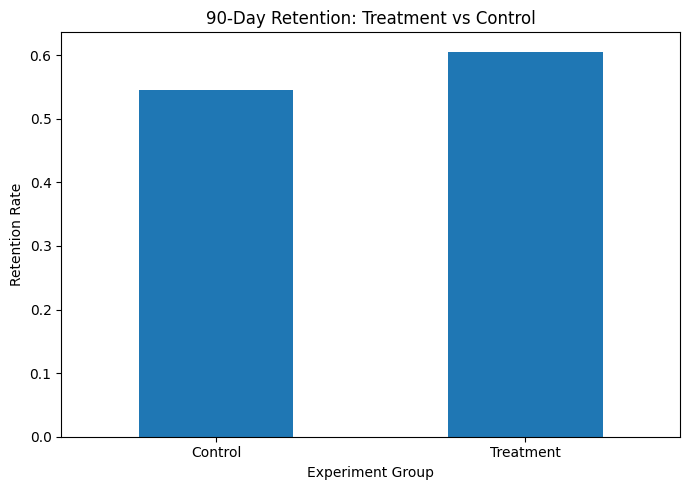

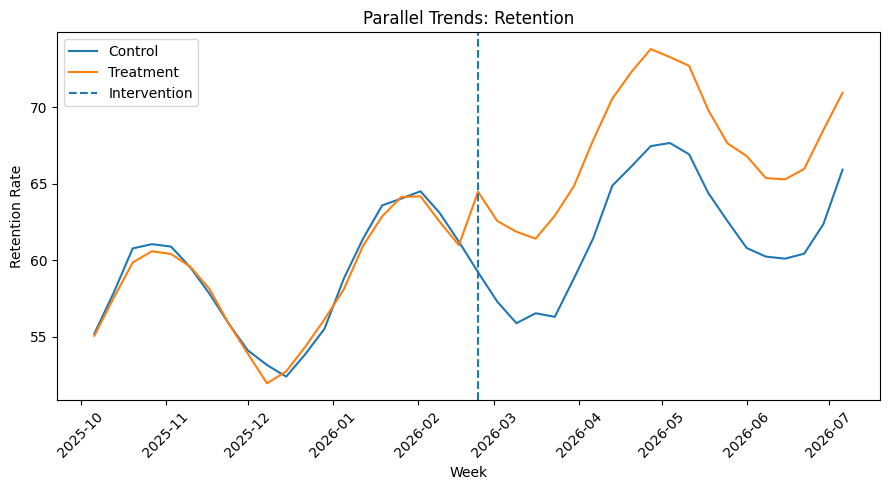

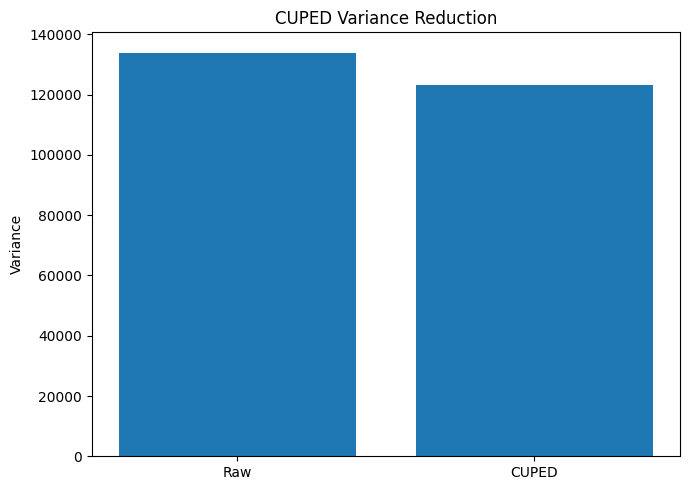

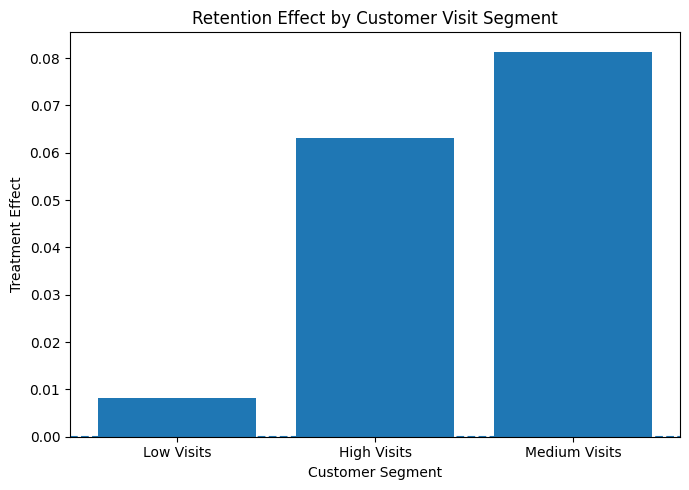


========== 10. COMBINED EFFECT ESTIMATES ==========


,Effect,CI_Lower,CI_Upper,P_Value
Analysis,,,,
90-Day Retention,0.060500,0.042844,0.078156,1.949812e-11
Revenue Per Visit,31.838097,18.750949,44.925244,1.880266e-06
No-Show Rate,-0.033500,-0.044474,-0.022526,2.248258e-09
retention_rate,5.918621,5.619135,6.218108,0.000000e+00
revenue_per_visit,54.159668,46.985336,61.334000,1.555908e-49
no_show_rate,-2.004453,-2.159007,-1.849900,1.539497e-142



========== 11. CREATING DESIGN DOCUMENT ==========

========== 12. CREATING DECISION MEMO ==========

========== 13. PACKAGING FINAL RESULTS ==========

          ANALYSIS COMPLETED

Final Summary
SRM p-value: 1.0
Required sample per group: 2404
Estimated duration: 25 days
CUPED variance reduction: 8.07 %
Parallel trends: No statistically significant differential pre-trend detected

Generated Files:
- Decision_Memo.docx
- Experiment_Design.docx
- ab_retention.png
- ab_test_results.csv
- all_effect_estimates.csv
- cuped.png
- cuped_results.csv
- cuped_variance.png
- did_results.csv
- did_trends.png
- parallel_trends.csv
- power_analysis.csv
- randomisation_balance.csv
- sample_ratio_mismatch.csv
- segment_effects.png
- segmentation_results.csv
- segments.png

Final ZIP: Salon_Final_Submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

# ============================================================
# SALON & SPA CAUSAL INFERENCE - COMPLETE MASTER ANALYSIS
# Updated: Meaningful set_index() for every result table
# ============================================================

!pip -q install statsmodels scipy python-docx

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from docx import Document

np.random.seed(42)
os.makedirs("salon_results", exist_ok=True)

# ------------------------------------------------------------
# 0. DATA PREPARATION
# ------------------------------------------------------------

# Use existing Colab variables
ab = experiment.copy()
did = historical.copy()

# Clean column types
ab["treatment"] = ab["treatment"].astype(int)
did["treatment"] = did["treatment"].astype(int)
did["post"] = did["post"].astype(int)
did["week"] = pd.to_datetime(did["week"])

print("A/B Dataset Shape:", ab.shape)
print("Historical Dataset Shape:", did.shape)

# ------------------------------------------------------------
# 1. RANDOMISATION BALANCE
# ------------------------------------------------------------

print("\n========== 1. RANDOMISATION BALANCE ==========")

balance_results = []

for col in [
    "baseline_revenue",
    "baseline_visits",
    "baseline_retained",
    "baseline_no_show"
]:
    t = ab.loc[ab.treatment == 1, col]
    c = ab.loc[ab.treatment == 0, col]

    test = stats.ttest_ind(t, c, equal_var=False)

    balance_results.append({
        "Variable": col,
        "Treatment_Mean": t.mean(),
        "Control_Mean": c.mean(),
        "P_Value": test.pvalue
    })

balance_df = pd.DataFrame(balance_results)
balance_df.set_index("Variable", inplace=True)

display(balance_df)

balance_df.to_csv(
    "salon_results/randomisation_balance.csv",
    index=True
)

# ------------------------------------------------------------
# 2. SAMPLE RATIO MISMATCH
# ------------------------------------------------------------

print("\n========== 2. SAMPLE RATIO MISMATCH ==========")

group_counts = ab["group"].value_counts()

observed = np.array([
    group_counts.get("Control", 0),
    group_counts.get("Treatment", 0)
])

srm_stat, srm_p = stats.chisquare(
    observed,
    f_exp=[len(ab)/2, len(ab)/2]
)

srm_df = pd.DataFrame({
    "Group": ["Control", "Treatment"],
    "Observed_Count": observed
})

srm_df.set_index("Group", inplace=True)

display(srm_df)

print("Chi-square:", srm_stat)
print("SRM p-value:", srm_p)
print("SRM Status:", "PASS" if srm_p >= 0.01 else "FAIL")

srm_df.to_csv(
    "salon_results/sample_ratio_mismatch.csv",
    index=True
)

# ------------------------------------------------------------
# 3. A/B TESTING WITH 95% CONFIDENCE INTERVALS
# ------------------------------------------------------------

print("\n========== 3. A/B TEST RESULTS ==========")

def bootstrap_ci(treatment, control, iterations=3000):
    treatment = np.asarray(treatment)
    control = np.asarray(control)

    differences = []

    for _ in range(iterations):
        t = np.random.choice(
            treatment, len(treatment), replace=True
        )
        c = np.random.choice(
            control, len(control), replace=True
        )
        differences.append(t.mean() - c.mean())

    return np.percentile(differences, [2.5, 97.5])


metrics = {
    "90-Day Retention": "retained_90d",
    "Revenue Per Visit": "revenue_per_visit",
    "No-Show Rate": "no_show"
}

analysis_results = []

for metric_name, column in metrics.items():

    t = ab.loc[ab.treatment == 1, column].values
    c = ab.loc[ab.treatment == 0, column].values

    effect = t.mean() - c.mean()

    test = stats.ttest_ind(
        t, c, equal_var=False
    )

    se = np.sqrt(
        t.var(ddof=1)/len(t) +
        c.var(ddof=1)/len(c)
    )

    ci_lower = effect - 1.96 * se
    ci_upper = effect + 1.96 * se

    boot_lower, boot_upper = bootstrap_ci(t, c)

    analysis_results.append({
        "Metric": metric_name,
        "Treatment_Mean": t.mean(),
        "Control_Mean": c.mean(),
        "Effect": effect,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper,
        "Bootstrap_Lower": boot_lower,
        "Bootstrap_Upper": boot_upper,
        "P_Value": test.pvalue
    })

    print(f"\n{metric_name}")
    print("Treatment Mean:", round(t.mean(), 4))
    print("Control Mean:", round(c.mean(), 4))
    print("Effect:", round(effect, 4))
    print("95% CI:", round(ci_lower, 4), "to", round(ci_upper, 4))
    print("Bootstrap CI:", round(boot_lower, 4), "to", round(boot_upper, 4))
    print("P-value:", round(test.pvalue, 6))

ab_results = pd.DataFrame(analysis_results)
ab_results.set_index("Metric", inplace=True)

display(ab_results)

ab_results.to_csv(
    "salon_results/ab_test_results.csv",
    index=True
)

# ------------------------------------------------------------
# 4. POWER ANALYSIS
# ------------------------------------------------------------

print("\n========== 4. POWER ANALYSIS ==========")

baseline = 0.55
target = 0.59
alpha = 0.05
power = 0.80

effect_size = proportion_effectsize(
    target, baseline
)

sample_per_group = NormalIndPower().solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1,
    alternative="two-sided"
)

sample_per_group = int(np.ceil(sample_per_group))
total_sample = sample_per_group * 2

# Planning assumption, not measured enrollment rate
daily_enrollment = 200
duration_days = int(np.ceil(total_sample / daily_enrollment))

power_df = pd.DataFrame({
    "Measure": [
        "Baseline Retention",
        "Target Retention",
        "Minimum Detectable Effect",
        "Significance Level",
        "Statistical Power",
        "Sample Per Group",
        "Total Sample",
        "Assumed Daily Enrollment",
        "Estimated Duration (Days)"
    ],
    "Value": [
        baseline,
        target,
        target - baseline,
        alpha,
        power,
        sample_per_group,
        total_sample,
        daily_enrollment,
        duration_days
    ]
})

power_df.set_index("Measure", inplace=True)
display(power_df)

power_df.to_csv(
    "salon_results/power_analysis.csv",
    index=True
)

# ------------------------------------------------------------
# 5. CUPED VARIANCE REDUCTION
# ------------------------------------------------------------

print("\n========== 5. CUPED ANALYSIS ==========")

cuped = ab.copy()

covariance = np.cov(
    cuped["revenue_per_visit"],
    cuped["baseline_revenue"],
    ddof=1
)[0, 1]

theta = covariance / cuped["baseline_revenue"].var(ddof=1)

cuped["adjusted_revenue"] = (
    cuped["revenue_per_visit"]
    - theta * (
        cuped["baseline_revenue"]
        - cuped["baseline_revenue"].mean()
    )
)

raw_variance = cuped["revenue_per_visit"].var()
adjusted_variance = cuped["adjusted_revenue"].var()

variance_reduction = (
    1 - adjusted_variance / raw_variance
) * 100

raw_multiplier = raw_variance / adjusted_variance

t = cuped.loc[
    cuped.treatment == 1, "adjusted_revenue"
]

c = cuped.loc[
    cuped.treatment == 0, "adjusted_revenue"
]

cuped_effect = t.mean() - c.mean()

cuped_test = stats.ttest_ind(
    t, c, equal_var=False
)

cuped_se = np.sqrt(
    t.var(ddof=1)/len(t) +
    c.var(ddof=1)/len(c)
)

cuped_ci_lower = cuped_effect - 1.96 * cuped_se
cuped_ci_upper = cuped_effect + 1.96 * cuped_se

cuped_df = pd.DataFrame({
    "Measure": [
        "CUPED Theta",
        "Raw Variance",
        "Adjusted Variance",
        "Variance Reduction (%)",
        "Effective Sample Multiplier",
        "Adjusted Treatment Effect",
        "Adjusted CI Lower",
        "Adjusted CI Upper",
        "Adjusted P-Value",
        "Approximate Adjusted Duration (Days)"
    ],
    "Value": [
        theta,
        raw_variance,
        adjusted_variance,
        variance_reduction,
        raw_multiplier,
        cuped_effect,
        cuped_ci_lower,
        cuped_ci_upper,
        cuped_test.pvalue,
        int(np.ceil(duration_days / raw_multiplier))
    ]
})

cuped_df.set_index("Measure", inplace=True)
display(cuped_df)

cuped_df.to_csv(
    "salon_results/cuped_results.csv",
    index=True
)

# ------------------------------------------------------------
# 6. DIFFERENCE-IN-DIFFERENCES
# ------------------------------------------------------------

print("\n========== 6. DIFFERENCE-IN-DIFFERENCES ==========")

did_results_list = []

for outcome in [
    "retention_rate",
    "revenue_per_visit",
    "no_show_rate"
]:

    model = smf.ols(
        f"{outcome} ~ treatment * post + C(outlet_id) + C(week)",
        data=did
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": did["outlet_id"]}
    )

    term = "treatment:post"

    effect = model.params[term]
    ci = model.conf_int().loc[term]
    p_value = model.pvalues[term]

    did_results_list.append({
        "Outcome": outcome,
        "DiD_Effect": effect,
        "CI_Lower": ci.iloc[0],
        "CI_Upper": ci.iloc[1],
        "P_Value": p_value
    })

    print(f"\nOutcome: {outcome}")
    print("DiD Effect:", round(effect, 4))
    print("95% CI:", ci.values)
    print("P-value:", round(p_value, 6))

did_results = pd.DataFrame(did_results_list)
did_results.set_index("Outcome", inplace=True)

display(did_results)

did_results.to_csv(
    "salon_results/did_results.csv",
    index=True
)

# ------------------------------------------------------------
# 7. PARALLEL TRENDS CHECK
# ------------------------------------------------------------

print("\n========== 7. PARALLEL TRENDS CHECK ==========")

did["week_number"] = (
    did["week"] - did["week"].min()
).dt.days / 7

pre = did[did.post == 0].copy()

pre_model = smf.ols(
    "retention_rate ~ treatment * week_number + C(outlet_id)",
    data=pre
).fit(
    cov_type="cluster",
    cov_kwds={"groups": pre["outlet_id"]}
)

trend_effect = pre_model.params["treatment:week_number"]
trend_p = pre_model.pvalues["treatment:week_number"]
trend_ci = pre_model.conf_int().loc["treatment:week_number"]

parallel_status = (
    "No statistically significant differential pre-trend detected"
    if trend_p >= 0.05
    else "Differential pre-trend detected; DiD interpretation requires caution"
)

parallel_df = pd.DataFrame({
    "Measure": [
        "Pre-Trend Effect",
        "CI Lower",
        "CI Upper",
        "P-Value"
    ],
    "Value": [
        trend_effect,
        trend_ci.iloc[0],
        trend_ci.iloc[1],
        trend_p
    ]
})

parallel_df.set_index("Measure", inplace=True)
display(parallel_df)

print("Assessment:", parallel_status)

parallel_df.to_csv(
    "salon_results/parallel_trends.csv",
    index=True
)

# ------------------------------------------------------------
# 8. CUSTOMER SEGMENTATION
# ------------------------------------------------------------

print("\n========== 8. CUSTOMER SEGMENTATION ==========")

ab["visit_segment"] = pd.cut(
    ab["baseline_visits"],
    bins=[-1, 1, 3, 100],
    labels=["Low Visits", "Medium Visits", "High Visits"]
)

ab["value_segment"] = np.where(
    ab["baseline_revenue"] >= ab["baseline_revenue"].median(),
    "High Value",
    "Low Value"
)

segment_results_list = []

for segment_col in [
    "visit_segment",
    "value_segment",
    "outlet_id"
]:

    for segment in ab[segment_col].dropna().unique():

        subset = ab[ab[segment_col] == segment]

        t = subset[subset.treatment == 1]["retained_90d"]
        c = subset[subset.treatment == 0]["retained_90d"]

        if len(t) > 5 and len(c) > 5:

            effect = t.mean() - c.mean()

            se = np.sqrt(
                t.var(ddof=1)/len(t) +
                c.var(ddof=1)/len(c)
            )

            segment_results_list.append({
                "Segment_Type": segment_col,
                "Segment": str(segment),
                "Treatment_N": len(t),
                "Control_N": len(c),
                "Effect": effect,
                "CI_Lower": effect - 1.96*se,
                "CI_Upper": effect + 1.96*se
            })

segments = pd.DataFrame(segment_results_list)

segments.set_index(
    ["Segment_Type", "Segment"],
    inplace=True
)

display(segments)

segments.to_csv(
    "salon_results/segmentation_results.csv",
    index=True
)

# ------------------------------------------------------------
# 9. VISUALISATIONS
# ------------------------------------------------------------

print("\n========== 9. GENERATING GRAPHS ==========")

# A/B retention comparison
plt.figure(figsize=(7, 5))

ab.groupby("group")["retained_90d"].mean().plot(kind="bar")

plt.title("90-Day Retention: Treatment vs Control")
plt.xlabel("Experiment Group")
plt.ylabel("Retention Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("salon_results/ab_retention.png", dpi=150)
plt.show()

# DiD parallel trends
trend = did.groupby(
    ["week", "region"]
)["retention_rate"].mean().reset_index()

plt.figure(figsize=(9, 5))

for region in trend["region"].unique():
    subset = trend[trend.region == region]
    plt.plot(
        subset["week"],
        subset["retention_rate"],
        label=region
    )

intervention_week = did.loc[
    did.post == 1, "week"
].min()

plt.axvline(
    intervention_week,
    linestyle="--",
    label="Intervention"
)

plt.title("Parallel Trends: Retention")
plt.xlabel("Week")
plt.ylabel("Retention Rate")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("salon_results/did_trends.png", dpi=150)
plt.show()

# CUPED variance comparison
plt.figure(figsize=(7, 5))

plt.bar(
    ["Raw", "CUPED"],
    [raw_variance, adjusted_variance]
)

plt.title("CUPED Variance Reduction")
plt.ylabel("Variance")
plt.tight_layout()
plt.savefig("salon_results/cuped_variance.png", dpi=150)
plt.show()

# Segment effect graph
visit_segments = segments.reset_index()
visit_segments = visit_segments[
    visit_segments["Segment_Type"] == "visit_segment"
]

plt.figure(figsize=(7, 5))

plt.bar(
    visit_segments["Segment"],
    visit_segments["Effect"]
)

plt.axhline(0, linestyle="--")
plt.title("Retention Effect by Customer Visit Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Treatment Effect")
plt.tight_layout()
plt.savefig("salon_results/segment_effects.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 10. COMBINED EFFECT ESTIMATES
# ------------------------------------------------------------

print("\n========== 10. COMBINED EFFECT ESTIMATES ==========")

ab_combined = ab_results.reset_index()
did_combined = did_results.reset_index()

ab_combined = ab_combined.rename(
    columns={"Metric": "Analysis"}
)

did_combined = did_combined.rename(
    columns={
        "Outcome": "Analysis",
        "DiD_Effect": "Effect"
    }
)

all_results = pd.concat(
    [
        ab_combined[
            ["Analysis", "Effect", "CI_Lower", "CI_Upper", "P_Value"]
        ],
        did_combined[
            ["Analysis", "Effect", "CI_Lower", "CI_Upper", "P_Value"]
        ]
    ],
    ignore_index=True
)

all_results.set_index("Analysis", inplace=True)

display(all_results)

all_results.to_csv(
    "salon_results/all_effect_estimates.csv",
    index=True
)

# ------------------------------------------------------------
# 11. EXPERIMENT DESIGN DOCUMENT
# ------------------------------------------------------------

print("\n========== 11. CREATING DESIGN DOCUMENT ==========")

doc = Document()

doc.add_heading(
    "Salon & Spa - Experiment Design Document", 0
)

doc.add_paragraph(
    "Data Disclosure: This project uses synthetic educational "
    "datasets. No real customer records were used."
)

doc.add_heading("1. Business Objective", level=1)
doc.add_paragraph(
    "Evaluate the impact of a customer retention initiative "
    "on 90-day retention, revenue per visit and no-show rate "
    "across a fictional chain of 22 salon and spa outlets."
)

doc.add_heading("2. Hypotheses", level=1)
doc.add_paragraph(
    "Null Hypothesis (H0): The initiative does not increase "
    "90-day customer retention."
)
doc.add_paragraph(
    "Alternative Hypothesis (H1): The initiative increases "
    "90-day customer retention."
)

doc.add_heading("3. Experimental Design", level=1)
doc.add_paragraph(
    "A customer-level randomized A/B experiment with a "
    "50% treatment group and 50% control group."
)

doc.add_heading("4. Metrics", level=1)
doc.add_paragraph(
    "Primary Metric: 90-day customer retention."
)
doc.add_paragraph(
    "Guardrail Metrics: Revenue per visit and no-show rate. "
    "Complaints, cancellations and outlet capacity should "
    "also be monitored during a real experiment."
)

doc.add_heading("5. Sample Size and Power", level=1)
doc.add_paragraph(
    f"Baseline retention: {baseline:.0%}. "
    f"Target retention: {target:.0%}. "
    f"Minimum detectable effect: {target-baseline:.0%}. "
    f"Significance level: {alpha}. "
    f"Statistical power: {power:.0%}. "
    f"Required sample: {sample_per_group} customers per group, "
    f"or {total_sample} in total."
)
doc.add_paragraph(
    f"Estimated duration: {duration_days} days, assuming "
    f"{daily_enrollment} eligible enrollments per day. "
    "This daily enrollment figure is a planning assumption."
)

doc.add_heading("6. Statistical Methods", level=1)
doc.add_paragraph(
    "Randomization balance checks, sample ratio mismatch, "
    "Welch's t-tests, bootstrap confidence intervals, "
    "CUPED adjustment, Difference-in-Differences and "
    "customer segment analysis."
)

doc.add_heading("7. Assumptions", level=1)
doc.add_paragraph(
    "Random assignment, consistent metric definitions, "
    "no material interference between experiment groups, "
    "and parallel trends for historical DiD analysis."
)

doc.add_heading("8. Limitations and Threats", level=1)
doc.add_paragraph(
    "The datasets are synthetic. Operational records include "
    "anonymous walk-ins, inconsistent service names and "
    "deliberate no-show misclassification. Unobserved "
    "confounding, seasonality, spillovers, measurement error "
    "and outlet-level differences may affect real-world estimates."
)

doc.save(
    "salon_results/Experiment_Design.docx"
)

# ------------------------------------------------------------
# 12. DECISION MEMO
# ------------------------------------------------------------

print("\n========== 12. CREATING DECISION MEMO ==========")

memo = Document()

memo.add_heading(
    "SALON & SPA - DECISION MEMO", 0
)

memo.add_paragraph("To: Management")
memo.add_paragraph(
    "Subject: Customer Retention Initiative Evaluation"
)
memo.add_paragraph(
    "Evidence Base: Synthetic educational data"
)

memo.add_heading("A/B Experiment Findings", level=1)

for metric, row in ab_results.iterrows():
    memo.add_paragraph(
        f"{metric}: Treatment effect = {row['Effect']:.4f}; "
        f"95% CI = [{row['CI_Lower']:.4f}, "
        f"{row['CI_Upper']:.4f}]; "
        f"p-value = {row['P_Value']:.5f}."
    )

memo.add_heading("Historical DiD Findings", level=1)

for outcome, row in did_results.iterrows():
    memo.add_paragraph(
        f"{outcome}: DiD effect = {row['DiD_Effect']:.4f}; "
        f"95% CI = [{row['CI_Lower']:.4f}, "
        f"{row['CI_Upper']:.4f}]; "
        f"p-value = {row['P_Value']:.5f}."
    )

memo.add_heading("Assumption Checks", level=1)
memo.add_paragraph(
    f"Sample Ratio Mismatch p-value: {srm_p:.5f}. "
    f"Parallel trends assessment: {parallel_status}. "
    f"CUPED variance reduction: {variance_reduction:.2f}%."
)

memo.add_heading("Recommendation", level=1)
memo.add_paragraph(
    "PROVISIONAL GO for further controlled evaluation only. "
    "The synthetic results demonstrate the analysis workflow "
    "but do not establish actual business impact. "
    "A real-world rollout should require validation using "
    "real operational data and a properly monitored experiment."
)

memo.add_heading("Threats to Causal Validity", level=1)
memo.add_paragraph(
    "Seasonality, selection bias, measurement errors, "
    "unobserved confounding, outlet differences, spillovers "
    "and incorrect appointment-status classification."
)

memo.save(
    "salon_results/Decision_Memo.docx"
)

# ------------------------------------------------------------
# 13. CREATE FINAL ZIP
# ------------------------------------------------------------

print("\n========== 13. PACKAGING FINAL RESULTS ==========")

zip_name = "Salon_Final_Submission.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:

    for root, dirs, files_list in os.walk("salon_results"):
        for file in files_list:
            full_path = os.path.join(root, file)
            z.write(full_path, arcname=full_path)

print("\n============================================")
print("          ANALYSIS COMPLETED")
print("============================================")

print("\nFinal Summary")
print("SRM p-value:", round(srm_p, 5))
print("Required sample per group:", sample_per_group)
print("Estimated duration:", duration_days, "days")
print("CUPED variance reduction:", round(variance_reduction, 2), "%")
print("Parallel trends:", parallel_status)

print("\nGenerated Files:")
for file in sorted(os.listdir("salon_results")):
    print("-", file)

print("\nFinal ZIP:", zip_name)

from google.colab import files
files.download(zip_name)


In [6]:
import gzip
import shutil

with open(
    "salon_appointments_synthetic_300k.csv", "rb"
) as source:
    with gzip.open(
        "salon_appointments_synthetic_300k.csv.gz", "wb"
    ) as target:
        shutil.copyfileobj(source, target)

print("Compressed dataset created successfully!")

Compressed dataset created successfully!


In [7]:
df.sample(
    n=50000,
    random_state=42
).to_csv(
    "salon_appointments_sample_50k.csv",
    index=False
)